In [1]:
import os
import geopandas as gpd
from shapely import wkt
import matplotlib.pyplot as plt

# Make catchment shapefile for upload to Google Earth Engine (GEE)

Trim unnecesary features and save to .shp, ready for upload to GEE as an asset. In addition:

* **Simplify geometry**: For small shapefiles (not many catchment polygons), don't need to simplify geometry and the geometry simplification is done in the GEE script. For lots of features, simplify this here instead, otherwise the upload of the .shp to GEE fails.

    Checked the simplification in GEE and I'd say it looks ok. Result of it is drastic reduction in file size, e.g. for all vannmiljø & Quantom catchments with OC data, reduce from around 400 MB to around 50 MB. Because of different thresholds for different catchment areas, can end up with boundaries between catchments being a bit disjointed, but think it's fine for zonal stats.

* **Reproject**: From (bitter ;-) experience, find that do not need to reproject from EPSG 25833 unless shapefiles include polygones in northeast Norway. If they do, then need to **reproject to WGS84** or the asset upload fails.

# User input

In [2]:
folder = r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments"

# Input filename
in_fname = "catchments_vm-rivs-quant-oc_v3-full.gpkg"

cat_id_col = "site_code"  # Only this and geometry columns are kept

# Params for simplifying geometry (e.g. match GEE script Sentinel2 B)
SIMPLIFY_GEOM = True
# SIMPLIFY_TOLERANCE_M = 25     # or 50
# SIMPLIFY_MIN_AREA_M2 = 4e6    # 4 km2

# Or, a tiered tolerance
def choose_tolerance(area):
    if area < 1e6:        # < 1 km²
        return 5          # very gentle (5 m)
    elif area < 4e6:      # 1–4 km² (10m)
        return 10
    elif area < 5e7:      # 4–50 km² (25m)
        return 25
    else:                 # > 50 km² (50m)
        return 50

# Reproject to WGS84?
reproject = True

# Output filepath (saved in same folder as in_fname)
out_fname = "catchments_vm-rivs-quant-oc_v3-full_for-gee.shp"

# Read in data & simplify geometry

In [3]:
in_cat_fpath = os.path.join(folder, in_fname)
raw_gdf = gpd.read_file(in_cat_fpath)
print(raw_gdf.crs)
print(raw_gdf.columns)
raw_gdf.head()

EPSG:25833
Index(['site_code', 'lon', 'lat', 'site_id', 'Name', 'start_year', 'end_year',
       'n_years', 'n_samples', 'av_freq', 'area_km2', 'geometry'],
      dtype='object')


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,area_km2,geometry
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,1008.505005,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,1009.065359,"POLYGON ((306680 6664180, 306760 6664180, 3067..."
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,6.702626,"POLYGON ((298520 6555300, 298640 6555300, 2986..."
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,15.372746,"POLYGON ((290660 6567260, 290680 6567260, 2906..."
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,42.290760,"POLYGON ((305560 6548480, 305560 6548500, 3055..."


In [4]:
# Cleanup
gdf = raw_gdf.copy()

# Any invalid geometries before we start?
invalid_mask = ~gdf.is_valid
n_invalid = invalid_mask.sum()

print(f"Invalid geometries BEFORE cleaning: {n_invalid}")

# --- REPROJECT (force consistency) ---
gdf = gdf.to_crs(25833)

# --- CLEAN GEOMETRIES ---
gdf["geometry"] = gdf.buffer(0)
print("Finished first buffering")

# --- COMPUTE AREA ---
gdf["area_m2"] = gdf.geometry.area

# --- CONDITIONAL SIMPLIFICATION ---
if SIMPLIFY_GEOM:
    # mask = gdf["area_m2"] >= SIMPLIFY_MIN_AREA_M2

    # gdf.loc[mask, "geometry"] = gdf.loc[mask, "geometry"].simplify(
    #     tolerance=SIMPLIFY_TOLERANCE_M,
    #     preserve_topology=True
    # )

    tolerances = gdf["area_m2"].apply(choose_tolerance)

    gdf["geometry"] = [
        geom.simplify(tol, preserve_topology=True)
        for geom, tol in zip(gdf.geometry, tolerances)
    ]
    print("Simplified geometry")

# --- FINAL CLEANUP ---
gdf["geometry"] = gdf.buffer(0)
print("Finished second buffering")

# --- KEEP ONLY NECESSARY FIELDS ---
gdf = gdf[[cat_id_col, "geometry"]]

invalid_after = (~gdf.is_valid).sum()
print(f"Invalid geometries AFTER cleaning: {invalid_after}")

gdf.head()

Invalid geometries BEFORE cleaning: 0
Finished first buffering
Simplified geometry
Finished second buffering
Invalid geometries AFTER cleaning: 0


,site_code,geometry
0,001-119928,"POLYGON ((306680 6664180, 306760 6664180, 3068..."
1,001-119929,"POLYGON ((306680 6664180, 306760 6664180, 3068..."
2,001-30653,"POLYGON ((298520 6555300, 298720 6555280, 2988..."
3,001-30683,"POLYGON ((290660 6567260, 290740 6567200, 2908..."
4,001-30687,"POLYGON ((305600 6548480, 305520 6548500, 3055..."


# QC

In [5]:
print(gdf.crs)

# Geometry type check
print("Geometry types:")
print(gdf.geom_type.value_counts())

# Area check
print("Min area:", gdf.geometry.area.min())

# Flag tiny polygons
tiny = gdf.geometry.area < 1   # < 1 m²
print(f"Tiny geometries: {tiny.sum()}")

# Check for non-polygons
non_poly = ~gdf.geom_type.isin(["Polygon", "MultiPolygon"])
print(f"Non-polygon geometries: {non_poly.sum()}")

EPSG:25833
Geometry types:
Polygon    8482
Name: count, dtype: int64
Min area: 315200.0
Tiny geometries: 0
Non-polygon geometries: 0


# Reproject & save

In [6]:
if reproject:
    gdf_wgs84 = gdf.copy()
    gdf_wgs84 = gdf.to_crs(4326)
    # Ensure coordinates are nicely rounded in the new CRS
    # (NB this doesn't simplify geometry shape)
    gdf_wgs84["geometry"] = gdf_wgs84.geometry.apply(
        lambda geom: wkt.loads(wkt.dumps(geom, rounding_precision=6))
    )

    out_fname = "catchments_vm-rivs-quant-oc_v3-full_wgs84_for-gee.shp"
    out_fpath = os.path.join(folder, out_fname)
    gdf_wgs84.to_file(out_fpath, driver="ESRI Shapefile")

    print(gdf_wgs84.crs)
    print(gdf_wgs84.head())

else:
    out_fname = "catchments_vm-rivs-quant-oc_v3-full_for-gee.shp"
    out_fpath = os.path.join(folder, out_fname)
    gdf.to_file(out_fpath, driver="ESRI Shapefile")

    print(gdf.crs)
    print(gdf.head())

EPSG:4326
    site_code                                           geometry
0  001-119928  POLYGON ((11.52579 60.06902, 11.52723 60.06906...
1  001-119929  POLYGON ((11.52579 60.06902, 11.52723 60.06906...
2   001-30653  POLYGON ((11.48294 59.08927, 11.48644 59.08918...
3   001-30683  POLYGON ((11.3346 59.19267, 11.33606 59.19217,...
4   001-30687  POLYGON ((11.61231 59.03141, 11.6109 59.03156,...


# Debugging reason for failed upload

Binary split approach is helpful for narrowing down problem catchment sets.

In [9]:
gdf["n_vertices"] = gdf.geometry.apply(
    lambda g: len(g.exterior.coords) if g.geom_type == "Polygon"
    else sum(len(p.exterior.coords) for p in g.geoms)
)

problem_mask = gdf["n_vertices"] > 5000

print("Highly complex:", problem_mask.sum())

Highly complex: 14


In [10]:
gdf.loc[gdf["n_vertices"] > 5000]

,site_code,geometry,n_vertices
257,002-118555,"POLYGON ((213440 6880480, 213300 6881100, 2134...",5407
310,002-124964,"POLYGON ((224960 6795100, 224600 6795680, 2243...",7817
393,002-28368,"POLYGON ((224960 6795100, 224600 6795680, 2243...",7642
442,002-30580,"POLYGON ((213440 6880480, 213400 6880940, 2133...",5403
477,002-30777,"POLYGON ((224960 6795100, 224600 6795680, 2243...",8349
485,002-38516,"POLYGON ((224960 6795100, 224600 6795680, 2243...",8373
731,002-60042,"POLYGON ((224960 6795100, 224600 6795680, 2243...",7666
732,002-60282,"POLYGON ((224960 6795100, 224600 6795680, 2243...",8373
733,002-60283,"POLYGON ((224960 6795100, 224600 6795680, 2243...",8379
734,002-60284,"POLYGON ((233560 6784440, 233980 6784580, 2339...",8390


In [36]:
# Split in two and save

gdf = gdf[[cat_id_col, "geometry"]]

# Output filepath (saved in same folder as in_fname)
out_fname_part1 = "catchments_vm-rivs-quant-oc_v3-full_for-gee_part1.shp"
out_fpath_part1 = os.path.join(folder, out_fname_part1)
gdf.iloc[:4000].to_file(out_fpath_part1, driver="ESRI Shapefile")

out_fname_part2 = "catchments_vm-rivs-quant-oc_v3-full_for-gee_part2.shp"
out_fpath_part2 = os.path.join(folder, out_fname_part2)
gdf.iloc[4000:].to_file(out_fpath_part2, driver="ESRI Shapefile")

# Automate a bit more from here

In [38]:
def export_split(gdf, folder, base_name, start, end):
    subset = gdf.iloc[start:end]
    fname = f"{base_name}_{start}_{end}.shp"
    fpath = os.path.join(folder, fname)

    print(f"Exporting {start}:{end} (n={len(subset)})")

    subset.to_file(fpath, driver="ESRI Shapefile")

    return fpath


def split_range(start, end):
    mid = (start + end) // 2
    return (start, mid), (mid, end)

In [39]:
# # Start with full dataset -> identify failing part
# start, end = 0, len(gdf)

# (a_start, a_end), (b_start, b_end) = split_range(start, end)

# export_split(gdf, folder, "test_a", a_start, a_end)
# export_split(gdf, folder, "test_b", b_start, b_end)

In [40]:
# Repeat on failing range: part 2 failed first time
start, end = 4000, len(gdf)

# # Or if starting from scratch
# test_b failed
# start, end = b_start, b_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_a", a_start, a_end)
export_split(gdf, folder, "test_b", b_start, b_end)

Exporting 4000:6241 (n=2241)
Exporting 6241:8482 (n=2241)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_b_6241_8482.shp'

In [41]:
# Part 2b failed, so split again
start, end = b_start, b_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_2b1", a_start, a_end)
export_split(gdf, folder, "test_2b2", b_start, b_end)

Exporting 6241:7361 (n=1120)
Exporting 7361:8482 (n=1121)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_2b2_7361_8482.shp'

In [42]:
# Part 2b1 succeeded, part 2b2 failed (i.e. "b" from previous split), so split again
start, end = b_start, b_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_2b2a", a_start, a_end)
export_split(gdf, folder, "test_2b2b", b_start, b_end)

Exporting 7361:7921 (n=560)
Exporting 7921:8482 (n=561)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_2b2b_7921_8482.shp'

In [43]:
# Part 2b2a succeeded, part 2b2b failed (i.e. "b" from previous split), so split again
start, end = b_start, b_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_2b2b-a", a_start, a_end)
export_split(gdf, folder, "test_2b2b-b", b_start, b_end)

Exporting 7921:8201 (n=280)
Exporting 8201:8482 (n=281)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_2b2b-b_8201_8482.shp'

In [45]:
# Part 2b2bb failed (i.e. "b" from previous split), so split again
start, end = b_start, b_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_2b2bb-a", a_start, a_end)
export_split(gdf, folder, "test_2b2bb-b", b_start, b_end)

Exporting 8201:8341 (n=140)
Exporting 8341:8482 (n=141)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_2b2bb-b_8341_8482.shp'

In [44]:
# b failed again (suspecting northern Norway now)

,site_code,geometry
8477,313-99151,"POLYGON ((330520 6675840, 331120 6675820, 3315..."
8478,314-46646,"POLYGON ((313080 6620240, 313140 6620200, 3131..."
8479,314-48074,"POLYGON ((323300 6634640, 323200 6634960, 3231..."
8480,314-62046,"POLYGON ((315400 6600460, 315640 6600460, 3156..."
8481,314-89994,"POLYGON ((317940 6629100, 317960 6629100, 3179..."


In [46]:
# Part 2b2bb failed (i.e. "b" from previous split), so split again
start, end = b_start, b_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_2b2bbb-a", a_start, a_end)
export_split(gdf, folder, "test_2b2bbb-b", b_start, b_end)

Exporting 8341:8411 (n=70)
Exporting 8411:8482 (n=71)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_2b2bbb-b_8411_8482.shp'

In [48]:
# Part 2b2bb-a failed (i.e. "a" from previous split), so split again
start, end = a_start, a_end

(a_start, a_end), (b_start, b_end) = split_range(start, end)

export_split(gdf, folder, "test_2b2bbbAa", a_start, a_end)
export_split(gdf, folder, "test_2b2bbbAb", b_start, b_end)

Exporting 8341:8358 (n=17)
Exporting 8358:8376 (n=18)


'/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments/test_2b2bbbAb_8358_8376.shp'

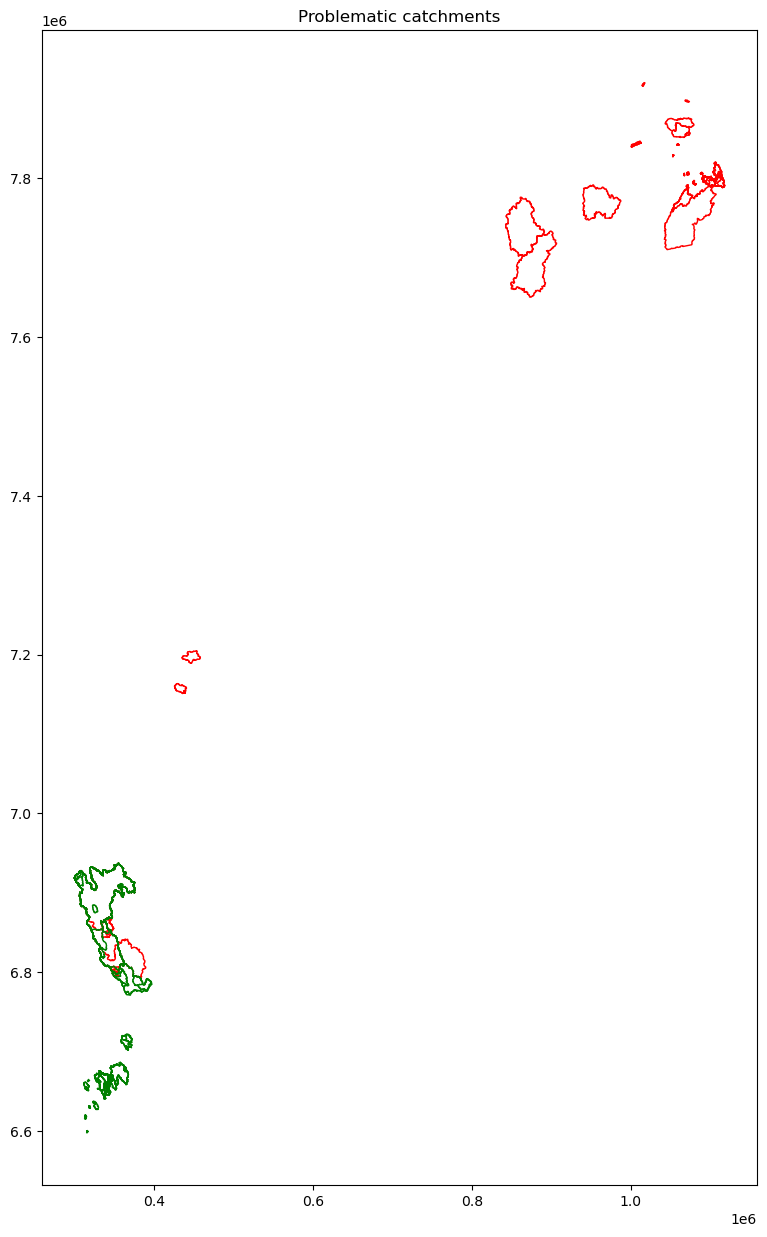

In [57]:
problem = gdf.iloc[8341:8411]  # All possible
# problem = gdf.iloc[8341:8358]
# problem2 = gdf.iloc[8358:8376]
fine = gdf.iloc[8411:8482]

fig, ax = plt.subplots(figsize=(15, 15))
problem.plot(ax=ax, edgecolor="red", facecolor="none")
# problem2.plot(ax=ax, edgecolor="blue", facecolor="none")
fine.plot(ax=ax, edgecolor="green", facecolor="none")
ax.set_title("Problematic catchments")
plt.show()
